# Análise exploratória: ocorrências da Defesa Civil (M'Boi Mirim)

**Projeto Integrador IV (UNIVESP).** *Sistema para análise de dados baseado em aprendizado de máquina aplicado às ocorrências da Defesa Civil.*

Este notebook examina os dados **antes** de qualquer modelo. Ele responde a três perguntas:

1. **Qualidade:** que problemas de digitação, padronização e consistência existem na base?
2. **Completude:** a base cobre todo o período ou há meses sem cadastro?
3. **Viabilidade:** os dados sustentam os dois modelos propostos no relatório parcial, a regressão (demanda de chamados) e a classificação (tipo de ocorrência)?

**Como executar**

- **Localmente:** na raiz do repositório, rode `pip install -r ml/requirements.txt` e abra este notebook.
- **No Google Colab:** a primeira célula clona o repositório e ajusta o caminho sozinha.

Os dados vêm da API pública do sistema (`/api/ocorrencias/`) e ficam guardados em `ml/dados/`, pasta que não vai para o git porque contém endereços. As regras de limpeza estão em `ml/limpeza.py`, para que os modelos usem exatamente a mesma limpeza.

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("defesa2.0").exists():
        !git clone -q https://github.com/allanwds/defesa2.0.git
    RAIZ = Path("defesa2.0").resolve()
else:
    RAIZ = Path.cwd().resolve()
    while not (RAIZ / "ml").is_dir() and RAIZ != RAIZ.parent:
        RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ml.dados import DIR_DADOS, carregar_ocorrencias
from ml.limpeza import (LAT_MAX, LAT_MIN, LON_MAX, LON_MIN, PERIODOS_COMPLETOS, chave_bairro, limpar,
                        marcar_periodos, ocorrencias_validas, padronizar_motivo)

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 140)

# Estilo dos gráficos: marcas finas, grade discreta, texto em tons neutros.
TEXTO, TEXTO_SEC, GRADE = "#0b0b0b", "#52514e", "#e4e3df"
AZUL, CINZA = "#2a78d6", "#c9c8c2"
CORES_GRUPO = {  # cor fixa por grupo, igual em todos os gráficos
    "Estrutural": "#2a78d6",
    "Arbóreo": "#eb6834",
    "Geológico": "#1baf7a",
    "Hidrológico": "#eda100",
    "Outros": "#8a8984",
}
ORDEM_GRUPO = list(CORES_GRUPO)
MESES = ["jan", "fev", "mar", "abr", "mai", "jun", "jul", "ago", "set", "out", "nov", "dez"]
DIAS = ["seg", "ter", "qua", "qui", "sex", "sáb", "dom"]


def eixo_meses(ax):
    # Rótulos de mês em português, sem depender do locale do sistema.
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: MESES[mdates.num2date(x).month - 1]))


plt.rcParams.update({
    "figure.dpi": 110,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRADE,
    "axes.labelcolor": TEXTO_SEC,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.axisbelow": True,
    "grid.color": GRADE,
    "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC,
    "ytick.color": TEXTO_SEC,
    "legend.frameon": False,
    "font.size": 10,
})

## 1. Carga dos dados

Na primeira execução os dados são baixados da API. Depois disso o notebook usa a cópia local. Para baixar de novo, troque para `carregar_ocorrencias(atualizar=True)`. O Render hiberna o serviço gratuito, então o primeiro download pode levar até um minuto.

In [2]:
bruto = carregar_ocorrencias()
print(f"{len(bruto)} registros, de {bruto['data'].min():%d/%m/%Y} a {bruto['data'].max():%d/%m/%Y}")

pd.DataFrame({
    "tipo": bruto.dtypes.astype(str),
    "nulos": bruto.isna().sum(),
    "valores distintos": bruto.nunique(),
})

774 registros, de 02/01/2024 a 08/05/2026


,tipo,nulos,valores distintos
id,int64,0,774
numero,int64,0,514
sigrc,int64,0,774
endereco,str,0,712
bairro,str,0,207
distrito,str,0,3
area_risco,int64,0,5
motivo,str,0,13
data,datetime64[us],0,240
latitude,float64,1,588


A base tem 11 campos. Os que interessam ao aprendizado de máquina são `data` (tempo), `bairro`, `distrito`, `latitude` e `longitude` (espaço), `area_risco` e `motivo`, que é o alvo da classificação. `numero` é a numeração anual da ocorrência e `sigrc` é o protocolo do sistema oficial. Como se verá na seção 4, `numero` é a chave para medir se a base está completa.

## 2. Qualidade dos dados

### 2.1 Motivo

O motivo é o alvo da classificação, então variações de grafia criam classes falsas.

In [3]:
bruto["motivo"].value_counts().to_frame("registros")

,registros
motivo,
Outros,140
Risco de desabamento,131
Risco de queda de árvore,128
Queda de árvore,97
Desabamento,76
Rachadura em Edificação,59
Erosão na via,52
Deslizamento,50
Alagamento,24


"Rachadura em Edificação", "Rachadura em edificação" e "rachadura em edificações " (com espaço no final) são a mesma classe. "Outros" é a categoria mais frequente, e a base não tem um campo de descrição que permita reclassificar esses registros.

### 2.2 Bairro

In [4]:
chaves = bruto["bairro"].map(chave_bairro)
print(f"{bruto['bairro'].nunique()} grafias distintas → {chaves.nunique()} bairros após a padronização")

variantes = bruto.groupby(chaves)["bairro"].agg(lambda s: " | ".join(sorted(set(s))))
variantes = variantes[bruto.groupby(chaves)["bairro"].nunique() > 1]
variantes.to_frame("grafias encontradas para o mesmo bairro").head(15)

207 grafias distintas → 134 bairros após a padronização


,grafias encontradas para o mesmo bairro
bairro,
alto da riviera,ALTO DA RIVIERA | Alto da Riviera
chacara florida,Chacara Florida | Chácara Florida | Chácara Fl...
chacara santana,Chacara Santana | Chácara Santana | chacara Sa...
chacara sonho azul,Chácara Sonho Azul | Chácara sonho azul | chác...
chacara vista alegre,Chacara Vista Alegre | Chacara Vista Alegrre
conjunto promorar,CONJUNTO PROMORAR | Conjunto Promorar
guarapiranga,GUARAPIRANGA | Guarapiranga
jardim angela,Jardim Ãngela | Jardim Angela | Jardim Ângela...
jardim aracati,Jardim Aracai | Jardim Aracati | Jd Aracati


O campo é texto livre. Ele acumula abreviações (Jd., Pq.), diferenças de maiúsculas e acentos, espaços duplos, erros de digitação ("Edwirges", "Riveira", "Jardimm") e um erro de codificação de caracteres ("Jardim  Ãngela"). Sem padronização, o mesmo bairro aparece como várias categorias diferentes.

### 2.3 Distrito

In [5]:
bruto["distrito"].value_counts().to_frame("registros")

,registros
distrito,
Jd. Angela,399
Jd. São Luis,362
Selecione,13


"Selecione" é o valor padrão do formulário de cadastro, salvo quando ninguém escolheu um distrito. Esses registros não têm distrito.

### 2.4 Registros que não são ocorrências

In [6]:
administrativos = bruto[bruto["bairro"].str.contains(r"\(", regex=True)]
administrativos[["numero", "data", "bairro", "motivo"]]

,numero,data,bairro,motivo
144,376,2025-07-15,Parque Novo Mundo ( Retirada de cobertores),Outros
156,364,2025-07-07,Alto do Pari ( retirada de uniforme),Outros
166,353,2025-06-27,Ipiranga ( Reunião),Outros
169,350,2025-06-24,Ermelino Matarazzo ( simulado),Outros
176,343,2025-06-16,Ponte Rasa ( Simulado),Outros


Reuniões, simulados e retiradas de materiais em outras regiões da cidade foram cadastrados como ocorrências do tipo "Outros". Eles precisam sair da análise, porque não representam demanda da população.

### 2.5 Coordenadas fora da região

15 registros com coordenada ausente ou fora de M'Boi Mirim


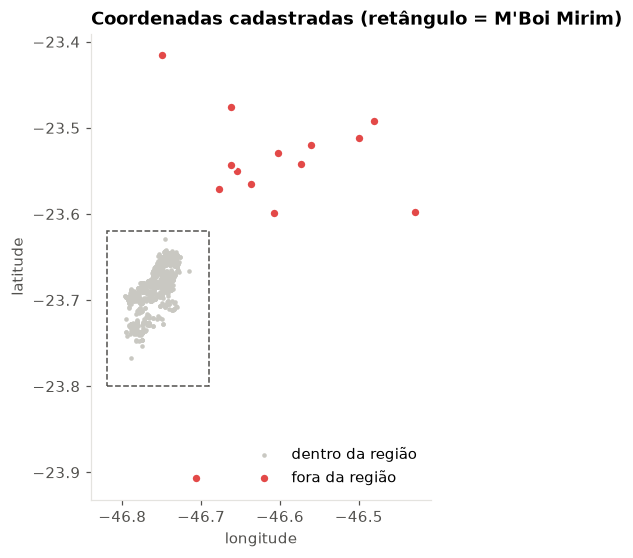

,numero,data,bairro,distrito,latitude,longitude
96,423,2025-08-15,Sé,Jd. São Luis,-23.550315,-46.654013
144,376,2025-07-15,Parque Novo Mundo ( Retirada de cobertores),Jd. São Luis,-23.520291,-46.561034
156,364,2025-07-07,Alto do Pari ( retirada de uniforme),Jd. São Luis,-23.528713,-46.602092
166,353,2025-06-27,Ipiranga ( Reunião),Jd. São Luis,-23.599305,-46.607410
169,350,2025-06-24,Ermelino Matarazzo ( simulado),Jd. São Luis,-23.491879,-46.480724
176,343,2025-06-16,Ponte Rasa ( Simulado),Jd. São Luis,-23.511350,-46.500202
178,340,2025-06-11,chacara florida,Jd. Angela,-23.907166,-46.706929
216,302,2025-05-12,Parque Europa,Jd. São Luis,-23.570699,-46.676811
217,301,2025-05-11,Vila Calu,Jd. Angela,-23.564616,-46.636963
228,290,2025-04-28,Vila Guiomar,Jd. Angela,-23.475692,-46.662689


In [7]:
fora = ~(bruto["latitude"].between(LAT_MIN, LAT_MAX) & bruto["longitude"].between(LON_MIN, LON_MAX))
print(f"{fora.sum()} registros com coordenada ausente ou fora de M'Boi Mirim")

fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(bruto.loc[~fora, "longitude"], bruto.loc[~fora, "latitude"], s=9, color=CINZA, linewidths=0, label="dentro da região")
ax.scatter(bruto.loc[fora, "longitude"], bruto.loc[fora, "latitude"], s=40, color="#e34948",
           edgecolor="white", linewidth=1.5, label="fora da região")
ax.add_patch(plt.Rectangle((LON_MIN, LAT_MIN), LON_MAX - LON_MIN, LAT_MAX - LAT_MIN,
                           fill=False, edgecolor=TEXTO_SEC, linestyle="--", linewidth=1))
ax.set_aspect(1 / np.cos(np.radians(-23.7)))
ax.grid(False)
ax.set_xlabel("longitude")
ax.set_ylabel("latitude")
ax.set_title("Coordenadas cadastradas (retângulo = M'Boi Mirim)")
ax.legend(loc="lower right")
plt.show()

bruto.loc[fora, ["numero", "data", "bairro", "distrito", "latitude", "longitude"]]

Parte desses pontos são as atividades administrativas da seção 2.4. O registro no bairro Sé (centro da cidade) provavelmente também é uma atividade, mas não tem marcação explícita e foi mantido. Os demais são bairros da região geocodificados no lugar errado (por exemplo, "Jardim Monte Azul" posicionado na zona leste). Esses registros continuam na análise temporal, mas a coordenada é descartada.

### 2.6 Protocolo SIGRC

In [8]:
digitos = bruto["sigrc"].astype(str).str.len()
print(digitos.value_counts().sort_index().rename("registros").rename_axis("dígitos").to_string())
bruto.loc[digitos != 8, ["numero", "data", "sigrc"]]

dígitos
4      1
7      3
8    767
9      3


,numero,data,sigrc
105,414,2025-08-06,3597695
114,405,2025-07-30,3552558
216,302,2025-05-12,350835955
298,218,2025-03-18,3692789
509,90,2026-01-28,365543395
690,29,2024-01-13,3193
722,18,2024-01-12,131925677


Quase todos os protocolos têm 8 dígitos. Os que fogem disso indicam erro de digitação: dígitos a mais ou a menos. Isso não afeta os modelos.

### 2.7 Número da ocorrência × data

In [9]:
def inversoes(grupo):
    grupo = grupo.sort_values(["data", "numero"])
    return int((grupo["numero"].diff() < 0).sum())

pd.DataFrame({
    "registros": bruto.groupby(bruto["data"].dt.year).size(),
    "números fora de ordem": bruto.groupby(bruto["data"].dt.year)[["data", "numero"]].apply(inversoes),
}).rename_axis("ano")

,registros,números fora de ordem
ano,,
2024,137,4
2025,511,17
2026,126,1


O número da ocorrência é sequencial dentro de cada ano. Quando os registros são ordenados por data, essa sequência deveria só crescer. As inversões indicam datas digitadas erradas, por exemplo fevereiro no lugar de janeiro. São poucas e não mudam a análise mensal de forma relevante.

### 2.8 Resumo dos problemas

In [10]:
resumo = pd.DataFrame([
    ("motivo", "grafias distintas a mais que motivos reais", bruto["motivo"].nunique() - bruto["motivo"].map(padronizar_motivo).nunique()),
    ("bairro", "grafias distintas a mais que bairros reais", bruto["bairro"].nunique() - chaves.nunique()),
    ("distrito", "valor padrão do formulário (\"Selecione\")", int((bruto["distrito"] == "Selecione").sum())),
    ("bairro/motivo", "atividades administrativas cadastradas como ocorrência", len(administrativos)),
    ("latitude/longitude", "ausentes ou fora de M'Boi Mirim", int(fora.sum())),
    ("sigrc", "protocolo com tamanho diferente de 8 dígitos", int((digitos != 8).sum())),
], columns=["campo", "problema", "registros"])
resumo

,campo,problema,registros
0,motivo,grafias distintas a mais que motivos reais,2
1,bairro,grafias distintas a mais que bairros reais,73
2,distrito,"valor padrão do formulário (""Selecione"")",13
3,bairro/motivo,atividades administrativas cadastradas como oc...,5
4,latitude/longitude,ausentes ou fora de M'Boi Mirim,15
5,sigrc,protocolo com tamanho diferente de 8 dígitos,7


## 3. Limpeza

A função `limpar` (em `ml/limpeza.py`) não apaga dados. Ela acrescenta colunas padronizadas e indicadores:

| Coluna | Regra |
|---|---|
| `motivo_padrao` | grafias unificadas numa lista fixa de motivos |
| `grupo_motivo` | motivos agrupados por natureza: Estrutural, Arbóreo, Geológico, Hidrológico e Outros |
| `bairro_chave`, `bairro_nome` | sem acentos e abreviações, com erros de digitação corrigidos; o nome de exibição é a grafia correta mais frequente |
| `distrito_padrao` | "Selecione" é preenchido com o distrito mais comum do mesmo bairro, ou com o da ocorrência mais próxima no mapa (`distrito_imputado` marca esses casos) |
| `coord_valida` | coordenadas fora de M'Boi Mirim passam a ser nulas |
| `atividade_administrativa` | reuniões, simulados e retiradas; `ocorrencias_validas` remove esses registros |
| `ano`, `mes`, `semana`, `dia_semana` | componentes de calendário |

In [11]:
df = limpar(bruto)
oc = ocorrencias_validas(df)

pd.DataFrame({
    "antes": [len(bruto), bruto["motivo"].nunique(), bruto["bairro"].nunique(), bruto["distrito"].nunique(),
              int(bruto["latitude"].notna().sum())],
    "depois": [len(oc), oc["motivo_padrao"].nunique(), oc["bairro_chave"].nunique(), oc["distrito_padrao"].nunique(),
               int(oc["coord_valida"].sum())],
}, index=["ocorrências", "motivos distintos", "bairros distintos", "distritos distintos", "com coordenada válida"])

,antes,depois
ocorrências,774,769
motivos distintos,13,11
bairros distintos,207,129
distritos distintos,3,2
com coordenada válida,773,759


## 4. Completude temporal

### 4.1 Registros por mês

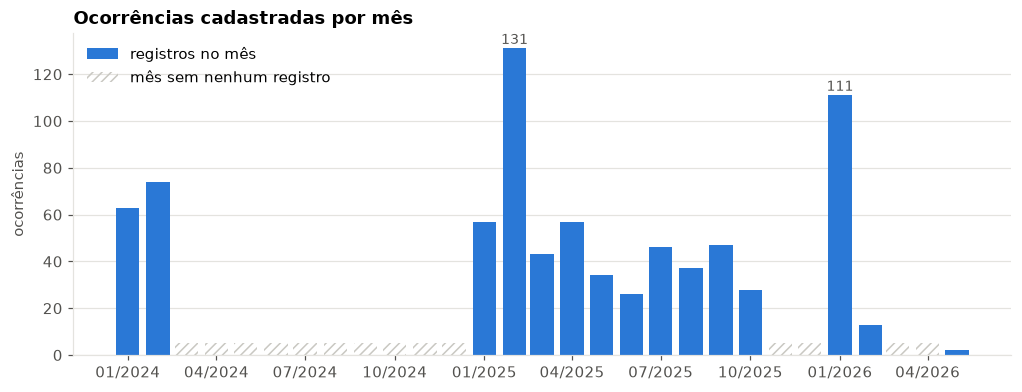

15 meses com registros e 14 meses sem nenhum, entre 2024-01 e 2026-05


In [12]:
mensal = oc.groupby(oc["data"].dt.to_period("M")).size()
todos_meses = pd.period_range(mensal.index.min(), mensal.index.max(), freq="M")
mensal = mensal.reindex(todos_meses, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 3.8))
x = mensal.index.to_timestamp()
vazio = mensal == 0
ax.bar(x[~vazio], mensal[~vazio], width=24, color=AZUL, label="registros no mês")
ax.bar(x[vazio], np.full(vazio.sum(), mensal.max() * 0.04), width=24, color="none",
       edgecolor=CINZA, hatch="////", linewidth=0, label="mês sem nenhum registro")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m/%Y"))
ax.set_ylabel("ocorrências")
ax.set_title("Ocorrências cadastradas por mês")
ax.legend(loc="upper left")
for xi, v in zip(x, mensal):
    if v >= 100:
        ax.annotate(str(v), (xi, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=TEXTO_SEC)
plt.show()

print(f"{(~vazio).sum()} meses com registros e {vazio.sum()} meses sem nenhum, entre {todos_meses[0]} e {todos_meses[-1]}")

A série tem buracos longos: de março a dezembro de 2024, novembro e dezembro de 2025, e março e abril de 2026. A Defesa Civil não ficou dez meses sem atender ocorrências, então esses buracos indicam **falta de cadastro no sistema**, não ausência de eventos. Um modelo treinado nessa série aprenderia o ritmo de digitação do grupo, não o ritmo das ocorrências.

### 4.2 Medindo a cobertura pelo número da ocorrência

Como `numero` é a numeração oficial e sequencial de cada ano, o maior número registrado mostra quantas ocorrências a Defesa Civil abriu até aquela data. Comparar esse valor com a quantidade de registros mostra quanto foi efetivamente cadastrado.

In [13]:
cobertura = bruto.groupby(bruto["data"].dt.year).agg(
    registros=("numero", "size"),
    maior_numero=("numero", "max"),
    ultima_data=("data", "max"),
)
cobertura["cobertura até a última data"] = (cobertura["registros"] / cobertura["maior_numero"]).map("{:.0%}".format)
cobertura["ultima_data"] = cobertura["ultima_data"].dt.strftime("%d/%m/%Y")
cobertura.rename_axis("ano")

,registros,maior_numero,ultima_data,cobertura até a última data
ano,,,,
2024,137,140,29/02/2024,98%
2025,511,534,07/10/2025,96%
2026,126,380,08/05/2026,33%


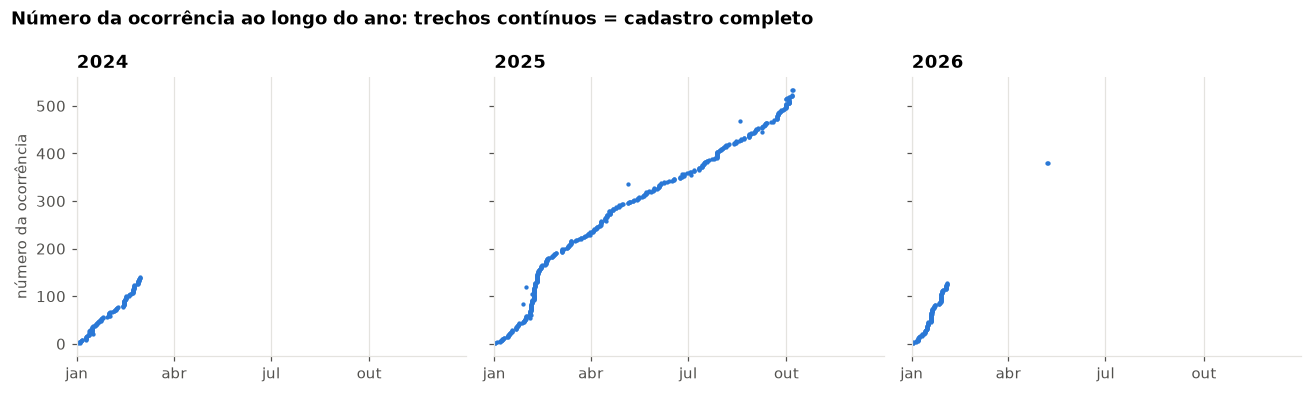

In [14]:
anos = sorted(bruto["data"].dt.year.unique())
fig, axes = plt.subplots(1, len(anos), figsize=(12, 3.6), sharey=True)
for ax, ano in zip(axes, anos):
    d = bruto[bruto["data"].dt.year == ano]
    ax.scatter(d["data"], d["numero"], s=8, color=AZUL, linewidths=0)
    ax.set_xlim(pd.Timestamp(ano, 1, 1), pd.Timestamp(ano, 12, 31))
    ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
    eixo_meses(ax)
    ax.set_title(str(ano))
    ax.grid(axis="both")
axes[0].set_ylabel("número da ocorrência")
fig.suptitle("Número da ocorrência ao longo do ano: trechos contínuos = cadastro completo", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

Leitura dos gráficos:

- **2024:** só janeiro e fevereiro foram cadastrados (números 1 a 140), com cobertura quase total nesse trecho. O resto do ano não existe na base.
- **2025:** a sequência é contínua de 2 de janeiro a 7 de outubro (até o número 534), com cerca de 96% de cobertura. A subida íngreme em fevereiro é o pico de chamados. Os poucos pontos fora da linha são as datas digitadas erradas da seção 2.7. É o único ano utilizável para estudar sazonalidade.
- **2026:** o cadastro vai até 3 de fevereiro (número 127). Dois registros de maio já têm os números 379 e 380. Portanto, **cerca de 250 ocorrências de fevereiro a maio de 2026 existem no sistema oficial e não foram cadastradas**.

Isso dá **12 meses completos**: janeiro e fevereiro de 2024, janeiro a setembro de 2025 e janeiro de 2026. Outubro de 2025 (só uma semana) e fevereiro de 2026 (só três dias) são parciais e, se forem contados como meses inteiros, parecem quedas de demanda que não aconteceram.

As colunas `periodo_completo`, `mes_completo` e `semana_completa` marcam esses trechos, e as próximas análises e os modelos devem respeitá-las.

In [15]:
# PERIODOS_COMPLETOS e marcar_periodos ficam em ml/limpeza.py, para que os modelos usem os mesmos trechos.
print(PERIODOS_COMPLETOS)
oc = marcar_periodos(oc)

print(f"{oc['periodo_completo'].sum()} de {len(oc)} ocorrências estão em períodos com cadastro completo")
print(f"Meses completos: {oc.loc[oc['mes_completo'], 'data'].dt.to_period('M').nunique()}")
print(f"Semanas completas (segunda a domingo): {oc.loc[oc['semana_completa'], 'semana'].nunique()}")

[('2024-01-01', '2024-02-29'), ('2025-01-01', '2025-10-07'), ('2026-01-01', '2026-02-03')]
767 de 769 ocorrências estão em períodos com cadastro completo
Meses completos: 12
Semanas completas (segunda a domingo): 51


## 5. O que acontece: motivos e grupos

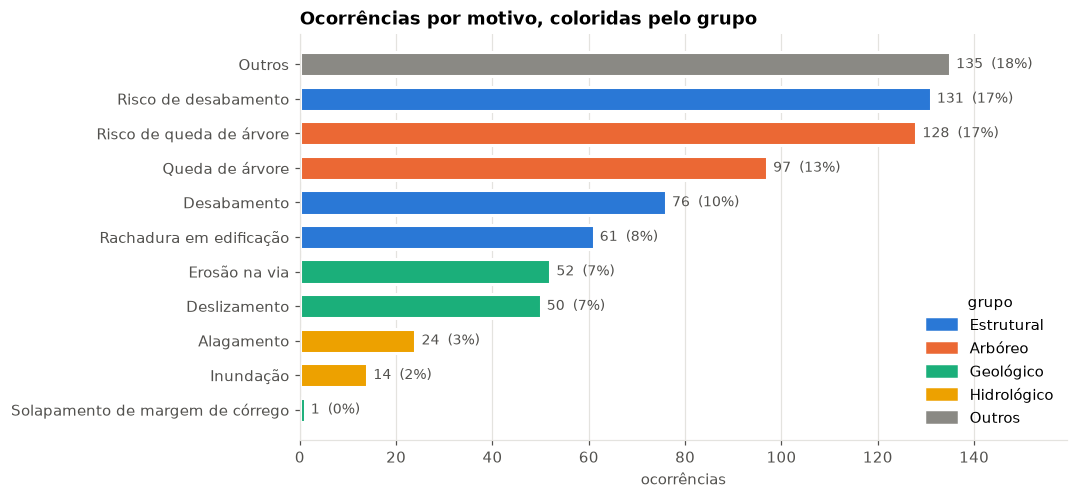

,ocorrências,%
grupo_motivo,,
Estrutural,268,34.9
Arbóreo,225,29.3
Geológico,103,13.4
Hidrológico,38,4.9
Outros,135,17.6


In [16]:
contagem = oc.groupby(["motivo_padrao", "grupo_motivo"]).size().reset_index(name="n").sort_values("n")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(contagem["motivo_padrao"], contagem["n"], height=0.7,
        color=contagem["grupo_motivo"].map(CORES_GRUPO), edgecolor="white", linewidth=2)
for y, (n, motivo) in enumerate(zip(contagem["n"], contagem["motivo_padrao"])):
    ax.annotate(f"{n}  ({n / len(oc):.0%})", (n, y), xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=TEXTO_SEC)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("ocorrências")
ax.set_title("Ocorrências por motivo, coloridas pelo grupo")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in CORES_GRUPO.values()],
          labels=ORDEM_GRUPO, loc="lower right", title="grupo")
ax.set_xlim(0, contagem["n"].max() * 1.18)
plt.show()

oc["grupo_motivo"].value_counts().reindex(ORDEM_GRUPO).to_frame("ocorrências").assign(
    **{"%": lambda t: (t["ocorrências"] / t["ocorrências"].sum() * 100).round(1)})

- **Estrutural** (riscos de desabamento, desabamentos e rachaduras) e **Arbóreo** (quedas e riscos de queda de árvore) somam cerca de dois terços das ocorrências.
- **Hidrológico** (alagamento e inundação) tem só cerca de 5%. Treinar um modelo para reconhecer essa classe vai exigir pesos de classe ou métricas por classe, porque a acurácia geral esconderia o erro nela.
- **Outros** continua com cerca de 18% e é uma caixa-preta: sem um campo de descrição, não há como saber que tipos de evento ele reúne.

Agrupar os 11 motivos em 5 classes deixa todas com pelo menos ~38 exemplos. Com 11 classes, três teriam menos de 25.

## 6. Quando acontece: sazonalidade

Só 2025 tem uma sequência longa e completa (janeiro a setembro), então a distribuição dos grupos ao longo do ano é estudada nesse ano.

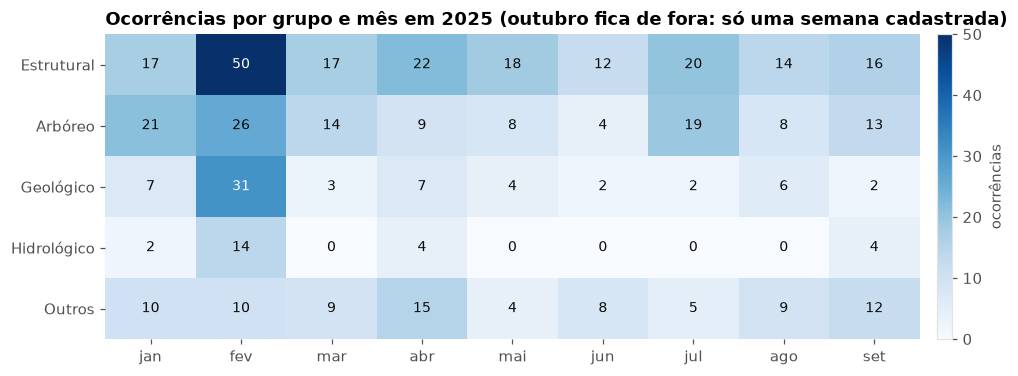

In [17]:
oc25 = oc[(oc["ano"] == 2025) & oc["mes_completo"]]
tabela = pd.crosstab(oc25["grupo_motivo"], oc25["mes"]).reindex(ORDEM_GRUPO)
tabela.columns = [MESES[m - 1] for m in tabela.columns]

fig, ax = plt.subplots(figsize=(10, 3.6))
im = ax.imshow(tabela.values, cmap="Blues", aspect="auto", vmin=0)
ax.set_xticks(range(tabela.shape[1]), tabela.columns)
ax.set_yticks(range(tabela.shape[0]), tabela.index)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
limite = tabela.values.max() * 0.55
for i in range(tabela.shape[0]):
    for j in range(tabela.shape[1]):
        v = tabela.values[i, j]
        ax.text(j, i, v, ha="center", va="center", fontsize=9, color="white" if v > limite else TEXTO)
ax.set_title("Ocorrências por grupo e mês em 2025 (outubro fica de fora: só uma semana cadastrada)")
plt.colorbar(im, ax=ax, fraction=0.025, pad=0.02, label="ocorrências")
plt.show()

In [18]:
por_mes = oc[oc["mes_completo"]].groupby(oc["data"].dt.to_period("M")).size().rename("ocorrências").to_frame()
por_mes["época"] = np.where(por_mes.index.month <= 2, "verão (jan e fev)", "mar a set")
print(por_mes.groupby("época")["ocorrências"].agg(meses="count", média="mean", mínimo="min", máximo="max").round(1).to_string())
por_mes[["ocorrências"]].T

                   meses  média  mínimo  máximo
época                                          
mar a set              7   41.4      26      57
verão (jan e fev)      5   87.2      57     131


data,2024-01,2024-02,2025-01,2025-02,2025-03,2025-04,2025-05,2025-06,2025-07,2025-08,2025-09,2026-01
ocorrências,63,74,57,131,43,57,34,26,46,37,47,111


- **Fevereiro de 2025** é o maior pico. Todos os grupos sobem, mas Geológico (31 casos, contra 2 a 7 nos outros meses) e Hidrológico (14 casos) se destacam, o que é coerente com as chuvas de verão.
- Os 5 meses de verão completos (janeiro e fevereiro de 2024 e 2025, janeiro de 2026) têm em média **o dobro** de ocorrências dos meses de março a setembro de 2025. A sazonalidade aparece nos três anos.
- Na única semana de outubro de 2025 cadastrada (fora do gráfico), 19 dos 28 registros são "Outros", proporção bem acima da média do ano.
- Com um único ano completo, porém, não dá para separar o efeito do mês do efeito da chuva daquele ano em particular. A **chuva**, ausente da base, é a principal candidata a explicar essas variações.

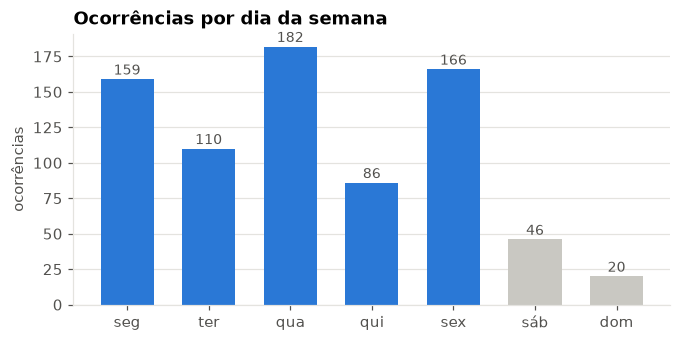

In [19]:
por_dia = oc["dia_semana"].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(7, 3.2))
ax.bar(DIAS, por_dia.values, width=0.65, color=[AZUL] * 5 + [CINZA] * 2)
for i, v in enumerate(por_dia.values):
    ax.annotate(str(v), (i, v), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=TEXTO_SEC)
ax.set_ylabel("ocorrências")
ax.set_title("Ocorrências por dia da semana")
plt.show()

Sábados e domingos têm poucas ocorrências, e mesmo entre os dias úteis há diferença grande: quinta-feira tem metade de quarta. Chuva e quedas de árvore não escolhem dia, então o mais provável é que a data registrada seja a do **atendimento ou do cadastro** (escala de vistorias), não a do evento. Para o modelo, isso significa duas coisas: o dia da semana entra como variável de calendário ("dia útil"), e a previsão por semana é mais robusta do que a previsão diária.

## 7. Onde acontece

129 bairros; 20 deles concentram metade das ocorrências; 61 têm 1 ou 2 registros
distrito_padrao
Jardim Ângela      409
Jardim São Luís    360


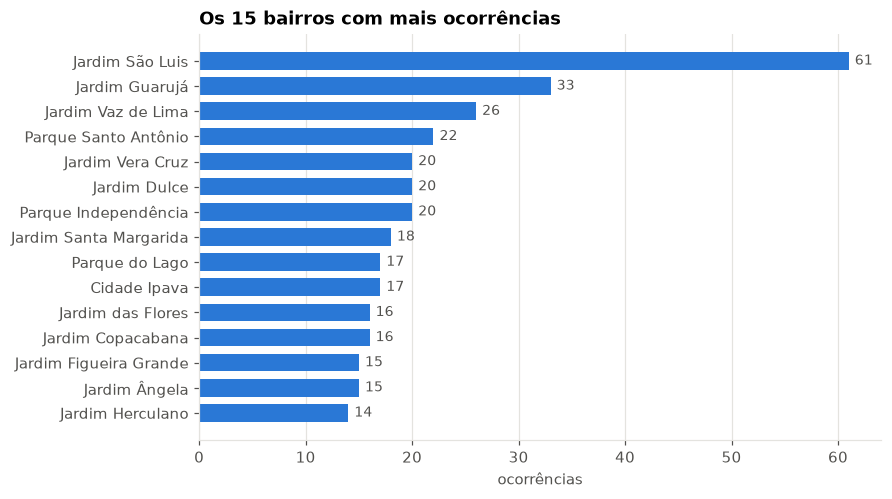

In [20]:
por_bairro = oc["bairro_nome"].value_counts()
acumulado = por_bairro.cumsum() / por_bairro.sum()
print(f"{len(por_bairro)} bairros; {(acumulado <= 0.5).sum() + 1} deles concentram metade das ocorrências; "
      f"{(por_bairro <= 2).sum()} têm 1 ou 2 registros")
print(oc["distrito_padrao"].value_counts().to_string())

top = por_bairro.head(15).sort_values()
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.barh(top.index, top.values, height=0.7, color=AZUL)
for y, v in enumerate(top.values):
    ax.annotate(str(v), (v, y), xytext=(4, 0), textcoords="offset points", va="center", fontsize=9, color=TEXTO_SEC)
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("ocorrências")
ax.set_title("Os 15 bairros com mais ocorrências")
plt.show()

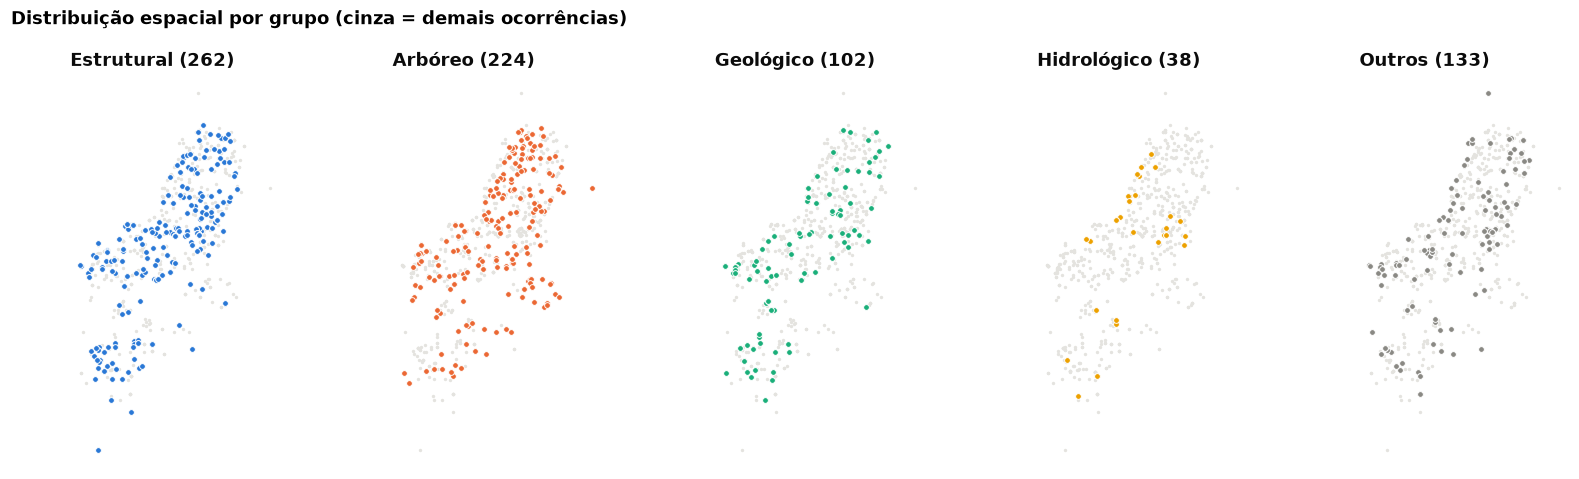

In [21]:
geo = oc[oc["coord_valida"]]
fig, axes = plt.subplots(1, len(ORDEM_GRUPO), figsize=(15, 4.4), sharex=True, sharey=True)
for ax, grupo in zip(axes, ORDEM_GRUPO):
    sel = geo["grupo_motivo"] == grupo
    ax.scatter(geo.loc[~sel, "longitude"], geo.loc[~sel, "latitude"], s=5, color=GRADE, linewidths=0)
    ax.scatter(geo.loc[sel, "longitude"], geo.loc[sel, "latitude"], s=14, color=CORES_GRUPO[grupo],
               edgecolor="white", linewidth=0.6)
    ax.set_title(f"{grupo} ({sel.sum()})", color=TEXTO)
    ax.set_aspect(1 / np.cos(np.radians(-23.7)))
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)
fig.suptitle("Distribuição espacial por grupo (cinza = demais ocorrências)", x=0.01, ha="left",
             fontweight="bold", fontsize=12)
fig.tight_layout()
plt.show()

- As ocorrências estão espalhadas por **mais de cem bairros**, com uma cauda longa: muitos bairros têm um ou dois registros. Usar o bairro diretamente como variável deixaria a maioria das categorias sem exemplos suficientes.
- A latitude e a longitude cobrem quase toda a base e não dependem da grafia. Agrupá-las em células (por exemplo, hexágonos H3 de ~1 km²) é a forma mais robusta de representar o espaço.
- Estrutural e Arbóreo cobrem toda a mancha urbana. Já Geológico e principalmente Hidrológico aparecem concentrados em poucos trechos, provavelmente encostas e margens de córrego. A localização fina (célula ou coordenada) deve ajudar justamente nas classes pequenas, e o distrito, por ser grosso demais, quase não ajuda. A seção 9 mede isso.

## 8. Área de risco

Distribuição geral: {0: 68.8, 1: 3.9, 2: 6.2, 3: 15.9, 4: 5.2}


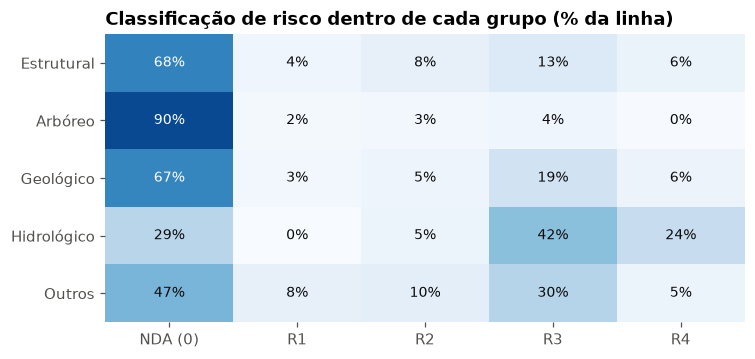

In [22]:
risco = pd.crosstab(oc["grupo_motivo"], oc["area_risco"], normalize="index").reindex(ORDEM_GRUPO)
risco.columns = ["NDA (0)", "R1", "R2", "R3", "R4"]
print("Distribuição geral:", (oc["area_risco"].value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

fig, ax = plt.subplots(figsize=(7.5, 3.4))
im = ax.imshow(risco.values, cmap="Blues", aspect="auto", vmin=0, vmax=1)
ax.set_xticks(range(risco.shape[1]), risco.columns)
ax.set_yticks(range(risco.shape[0]), risco.index)
ax.grid(False)
for spine in ax.spines.values():
    spine.set_visible(False)
for i in range(risco.shape[0]):
    for j in range(risco.shape[1]):
        v = risco.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=9, color="white" if v > 0.55 else TEXTO)
ax.set_title("Classificação de risco dentro de cada grupo (% da linha)")
plt.show()

- Cerca de 70% das ocorrências estão em locais sem classificação de risco (NDA).
- Ainda assim, a variável diferencia grupos. Dois terços das ocorrências **Hidrológicas** estão em áreas R3 ou R4, contra cerca de 20% no geral. As **Arbóreas** ficam 90% em NDA, como era de se esperar, já que queda de árvore não depende de risco geológico. As **Geológicas** ficam só um pouco acima da média em R3 e R4.
- `area_risco` é, portanto, uma variável útil para a classificação.

## 9. Viabilidade dos modelos propostos

### 9.1 Regressão: previsão da demanda de chamados

O relatório parcial propõe prever o volume **mensal** por região.

In [23]:
completos = oc[oc["semana_completa"]]
semanal = completos.groupby("semana").size()
print(f"Meses completos disponíveis: {oc.loc[oc['mes_completo'], 'data'].dt.to_period('M').nunique()}")
print(f"Semanas disponíveis: {len(semanal)} (média de {semanal.mean():.1f} ocorrências por semana, "
      f"desvio de {semanal.std():.1f})")

painel = completos.groupby(["semana", "distrito_padrao"]).size().unstack(fill_value=0)
print(f"\nPainel distrito × semana: {painel.size} linhas, média de {painel.values.mean():.1f}, "
      f"variância de {painel.values.var():.1f}, {np.mean(painel.values == 0):.0%} de semanas zeradas")

painel_b = completos.groupby(["semana", "bairro_chave"]).size().unstack(fill_value=0)
print(f"Painel bairro × semana: {painel_b.size} linhas, {np.mean(painel_b.values == 0):.0%} de semanas zeradas")

Meses completos disponíveis: 12
Semanas disponíveis: 51 (média de 14.3 ocorrências por semana, desvio de 11.0)

Painel distrito × semana: 102 linhas, média de 7.1, variância de 40.3, 2% de semanas zeradas
Painel bairro × semana: 6528 linhas, 91% de semanas zeradas


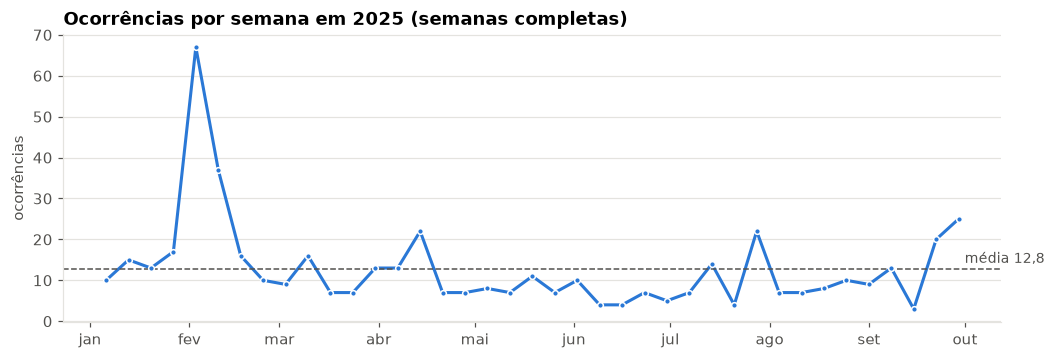

In [24]:
s25 = semanal[semanal.index.year == 2025]
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.plot(s25.index, s25.values, color=AZUL, linewidth=2)
ax.scatter(s25.index, s25.values, s=14, color=AZUL, edgecolor="white", linewidth=1, zorder=3)
ax.axhline(s25.mean(), color=TEXTO_SEC, linewidth=1, linestyle="--")
ax.annotate(f"média {s25.mean():.1f}".replace(".", ","), (s25.index[-1], s25.mean()), xytext=(4, 4), textcoords="offset points",
            fontsize=9, color=TEXTO_SEC)
eixo_meses(ax)
ax.set_ylabel("ocorrências")
ax.set_title("Ocorrências por semana em 2025 (semanas completas)")
plt.show()

- **A série mensal tem só 12 meses completos**, e apenas 9 consecutivos. Isso não basta para treinar e validar um Random Forest Regressor: o conjunto de teste teria 2 ou 3 meses.
- **Por semana** há 51 semanas completas, e o painel distrito × semana tem 102 linhas. A variância (~40) é quase seis vezes a média (~7). Essa sobredispersão é típica de contagens com picos de chuva, e favorece perdas de Poisson ou Tweedie e variáveis que expliquem os picos.
- **Por bairro × semana**, 91% das células são zero. Bairro é granular demais para a previsão de demanda.

**Implicação para a modelagem:** a unidade viável é **semana × distrito** (ou células espaciais maiores), com variáveis de calendário, contagens das semanas anteriores e, se possível, **chuva acumulada**. A validação precisa separar treino e teste por tempo.

### 9.2 Classificação: tipo de ocorrência

Antes de treinar, vale medir quanto cada variável candidata se associa ao grupo do motivo. O V de Cramér (com correção de viés) vai de 0, nenhuma associação, a 1, associação perfeita.

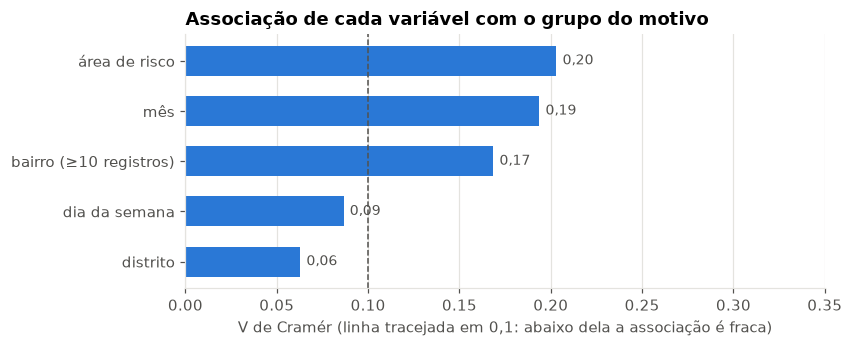

Referência simples: chutar sempre 'Estrutural' acerta 35% dos casos.


In [25]:
def cramers_v(x, y):
    # V de Cramér com a correção de viés de Bergsma (2013).
    tabela = pd.crosstab(x, y).values
    n = tabela.sum()
    esperado = tabela.sum(1, keepdims=True) * tabela.sum(0, keepdims=True) / n
    phi2 = ((tabela - esperado) ** 2 / esperado).sum() / n
    r, k = tabela.shape
    phi2c = max(0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc, kc = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2c / max(min(kc - 1, rc - 1), 1e-9))

bairro_top = oc["bairro_chave"].where(oc["bairro_chave"].map(oc["bairro_chave"].value_counts()) >= 10, "outros")
candidatas = {
    "área de risco": oc["area_risco"],
    "mês": oc["mes"],
    "bairro (≥10 registros)": bairro_top,
    "dia da semana": oc["dia_semana"],
    "distrito": oc["distrito_padrao"],
}
associacao = pd.Series({nome: cramers_v(v, oc["grupo_motivo"]) for nome, v in candidatas.items()}).sort_values()

fig, ax = plt.subplots(figsize=(7.5, 3))
ax.barh(associacao.index, associacao.values, height=0.6, color=AZUL)
for y, v in enumerate(associacao.values):
    ax.annotate(f"{v:.2f}".replace(".", ","), (v, y), xytext=(4, 0), textcoords="offset points", va="center",
                fontsize=9, color=TEXTO_SEC)
ax.axvline(0.1, color=TEXTO_SEC, linewidth=1, linestyle="--")
ax.set_xlim(0, max(0.35, associacao.max() * 1.25))
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
ax.set_xlabel("V de Cramér (linha tracejada em 0,1: abaixo dela a associação é fraca)")
ax.set_title("Associação de cada variável com o grupo do motivo")
plt.show()

base = oc["grupo_motivo"].value_counts(normalize=True)
print(f"Referência simples: chutar sempre '{base.index[0]}' acerta {base.iloc[0]:.0%} dos casos.")

- As associações mais fortes, `área de risco` (0,20), `mês` (0,19) e `bairro` (0,17), são moderadas. Dia da semana e distrito ficam abaixo de 0,1.
- A associação do mês deve ser lida com cuidado: só 2025 cobre de março a setembro, então o modelo pode confundir "mês" com "aquele ano em particular". Com mais anos de histórico, essa estimativa ficaria mais confiável.
- A **referência simples** (chutar sempre a classe mais frequente) acerta cerca de 35%. O classificador só terá valor se superá-la com folga, principalmente no **F1 macro**, que dá peso igual às classes pequenas.
- Com essas variáveis, é razoável esperar um classificador modesto. Acrescentar **chuva** e **características do terreno** (declividade, distância até córrego e mapeamento de risco do GeoSampa) é o que mais pode aumentar a separação entre os grupos.

## 10. Conclusões

### Principais achados

1. **A base é pequena e está incompleta.** São 769 ocorrências válidas. Pela numeração oficial, o cadastro só está completo em três trechos: janeiro e fevereiro de 2024, de janeiro a 7 de outubro de 2025 e de janeiro a 3 de fevereiro de 2026. Isso dá **12 meses completos**. O resto de 2024, novembro e dezembro de 2025 e cerca de 250 ocorrências de 2026 existem no sistema oficial, mas não neste sistema.
2. **A qualidade do cadastro exige limpeza**, que já está implementada em `ml/limpeza.py`:
   - 207 grafias para 129 bairros reais;
   - 5 atividades administrativas cadastradas como ocorrência;
   - 15 coordenadas ausentes ou fora da região;
   - 13 distritos com o valor padrão "Selecione";
   - motivos duplicados por grafia;
   - datas e protocolos SIGRC com erros de digitação.
3. **A sazonalidade é clara.** Os meses de verão têm em média o dobro de ocorrências (87 contra 41). Em fevereiro de 2025, o pico de eventos geológicos e hidrológicos aponta a chuva como principal fator.
4. **A data registrada parece ser a do atendimento, não a do evento**, porque há poucas ocorrências nos fins de semana e grande variação entre os dias úteis.
5. **Classes desbalanceadas:** Estrutural 35%, Arbóreo 29%, Outros 18%, Geológico 13% e Hidrológico 5%.
6. **Sinais moderados para a classificação.** Área de risco, mês e bairro têm V de Cramér entre 0,17 e 0,20. Distrito e dia da semana quase não informam.

### O que isso implica para os modelos

- **Regressão:** a previsão mensal não é viável. A unidade viável é **semana × distrito** (102 linhas em semanas completas), com perda de Poisson, validação separada por tempo e comparação com referências simples, como a média sazonal e a semana anterior. O Random Forest Regressor proposto no relatório entra como um dos modelos comparados.
- **Classificação:** prever os **5 grupos**, não os 11 motivos. Usar `class_weight="balanced"` e avaliar com F1 macro, matriz de confusão e log loss para as probabilidades. O modelo precisa superar a referência de 35% (chutar sempre "Estrutural").
- **Treinar só com os períodos completos**, usando as colunas `periodo_completo`, `mes_completo` e `semana_completa`.

In [26]:
saida = DIR_DADOS / "ocorrencias_limpas.csv"
oc.to_csv(saida, index=False)
print(f"{len(oc)} ocorrências limpas salvas em {saida.relative_to(RAIZ)}")

769 ocorrências limpas salvas em ml/dados/ocorrencias_limpas.csv
